# **Problem Statement**

## Business Context

Renewable energy sources play an increasingly important role in the global energy mix, as the effort to reduce the environmental impact of energy production increases.

Out of all the renewable energy alternatives, wind energy is one of the most developed technologies worldwide. The U.S Department of Energy has put together a guide to achieving operational efficiency using predictive maintenance practices.

Predictive maintenance uses sensor information and analysis methods to measure and predict degradation and future component capability. The idea behind predictive maintenance is that failure patterns are predictable and if component failure can be predicted accurately and the component is replaced before it fails, the costs of operation and maintenance will be much lower.

The sensors fitted across different machines involved in the process of energy generation collect data related to various environmental factors (temperature, humidity, wind speed, etc.) and additional features related to various parts of the wind turbine (gearbox, tower, blades, break, etc.).

## Objective

“ReneWind” is a company working on improving the machinery/processes involved in the production of wind energy using machine learning and has collected data of generator failure of wind turbines using sensors. They have shared a ciphered version of the data, as the data collected through sensors is confidential (the type of data collected varies with companies). Data has 40 predictors, 20000 observations in the training set and 5000 in the test set.

The objective is to build various classification models, tune them, and find the best one that will help identify failures so that the generators could be repaired before failing/breaking to reduce the overall maintenance cost.
The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model. These will result in repairing costs.
- False negatives (FN) are real failures where there is no detection by the model. These will result in replacement costs.
- False positives (FP) are detections where there is no failure. These will result in inspection costs.

It is given that the cost of repairing a generator is much less than the cost of replacing it, and the cost of inspection is less than the cost of repair.

“1” in the target variables should be considered as “failure” and “0” represents “No failure”.

## Data Description

The data provided is a transformed version of the original data which was collected using sensors.

- Train.csv - To be used for training and tuning of models.
- Test.csv - To be used only for testing the performance of the final best model.

Both the datasets consist of 40 predictor variables and 1 target variable.

# **Installing and Importing the necessary libraries**

In [1]:
# Installing the libraries with the specified version - takes about 60 seconds
!pip install --no-deps tensorflow==2.19.0 scikit-learn==1.6.1 matplotlib===3.10.0 seaborn==0.13.2 numpy==2.0.2 pandas==2.2.2 -q --user --no-warn-script-location

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.0/645.0 MB 2.8 MB/s eta 0:00:00


In [2]:
#Import the librarys that we will be using, do as much as we can in this initial one
import numpy as np
import pandas as pd
#SKLEARN
from sklearn.model_selection import train_test_split #split up data
from sklearn.model_selection import GridSearchCV #for tuning
from sklearn.preprocessing import StandardScaler #for scaling
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics #import these ahead of time prior to using
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
#in case we need these:
#from sklearn.ensemble import ( #these are all the tools for boosting et al
#    BaggingClassifier,
#    RandomForestClassifier,
#    AdaBoostClassifier,
#    GradientBoostingClassifier,
#)
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    make_scorer,
)
from sklearn.linear_model import LogisticRegression

# Libraries for building the neural network
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
# Setting seeds for reproducibility
SEED = 1
np.random.seed(SEED)
tf.random.set_seed(SEED)

#IMBLEARN
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

#SEABORN
import seaborn as sns #for graphs
from seaborn.categorical import countplot
#OTHERS
#from xgboost import XGBClassifier
#import category_encoders as ce
import matplotlib.pyplot as plt #for graphs


pd.set_option("display.max_columns", None) #we want to see all the columns
pd.set_option("display.max_rows", 100) #show us just 100 rows (not the full table)
import warnings
warnings.filterwarnings("ignore") #remove unneeded warnings
from datetime import datetime #needed for date/time conversions

In [3]:
#FUNCTIONS to be used during Model Building. Pre-building here to recall them later - I like having this pre-built near the librarys

#First is to Build Ann function to use
def build_ann(hidden_layers, optimizer, dropout=None, input_dim=40, seed=SEED):
    tf.random.set_seed(seed)
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden_layers:
        model.add(layers.Dense(units, activation="relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.Recall(name="recall"), keras.metrics.Precision(name="precision")],
    )
    return model

#Get the Accuracy, Recall, Precision and F1 for the model
def get_metrics(model, X, y):
    pred = (model.predict(X, verbose=0) > 0.5).astype(int).ravel()
    return {
        "Accuracy": accuracy_score(y, pred),
        "Recall": recall_score(y, pred),
        "Precision": precision_score(y, pred),
        "F1": f1_score(y, pred),
    }

#Plot Training and Validation Loss and Recall Curves
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history.history["loss"], label="Train Loss")
    axes[0].plot(history.history["val_loss"], label="Val Loss")
    axes[0].set_title(f"{title}: Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history.history["recall"], label="Train Recall")
    axes[1].plot(history.history["val_recall"], label="Val Recall")
    axes[1].set_title(f"{title}: Recall")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


#Plot a Confusion Matrix
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.title(title)
    plt.show()


#Evaluate the model on Train and Validation sets, store metrices for later
def evaluate_and_store(name, model, history, results_list, plot=True):
    train_metrics = get_metrics(model, X_train_scaled, y_train)
    val_metrics = get_metrics(model, X_val_scaled, y_val)
    print(f"===== {name} =====")
    print(f"Epochs run: {len(history.history['loss'])}")
    print("\nValidation set classification report:")
    val_pred = (model.predict(X_val_scaled, verbose=0) > 0.5).astype(int).ravel()
    print(classification_report(y_val, val_pred, target_names=["No Failure", "Failure"]))
    if plot:
        plot_history(history, name)
        plot_confusion(y_val, val_pred, f"{name}: Validation Confusion Matrix")
    results_list.append({
        "Model": name,
        "Train_Accuracy": train_metrics["Accuracy"], "Train_Recall": train_metrics["Recall"],
        "Train_Precision": train_metrics["Precision"], "Train_F1": train_metrics["F1"],
        "Val_Accuracy": val_metrics["Accuracy"], "Val_Recall": val_metrics["Recall"],
        "Val_Precision": val_metrics["Precision"], "Val_F1": val_metrics["F1"],
    })
    return train_metrics, val_metrics


#Store the data results
model_performance = []

# **Loading the Data**

In [4]:
#Load this first to get the google drive mounted (needs permissions - grant ok and hit continue) #this is my personal data path drive - so the one for the grader of this project will be different
from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/MyDrive/ColabNotebooks/Train.csv'
pathTest = '/content/drive/MyDrive/ColabNotebooks/Test.csv'

Mounted at /content/drive


In [5]:
#import the csv from my google drive above to DF (training) and DFTEST (for the testing that I will not touch until the end)
df = pd.read_csv(path) #train data
dftest = pd.read_csv(pathTest) #test data

# **Data Overview**

In [6]:
print("Shape of the training data:", df.shape)
print("Shape of the test data:", dftest.shape)

Shape of the training data: (20000, 41)
Shape of the test data: (5000, 41)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

In [8]:
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.464606,-4.679129,3.101546,0.506130,-0.221083,-2.032511,-2.910870,0.050714,-1.522351,3.761892,-5.714719,0.735893,0.981251,1.417884,-3.375815,-3.047303,0.306194,2.914097,2.269979,4.394876,-2.388299,0.646388,-1.190508,3.132986,0.665277,-2.510846,-0.036744,0.726218,-3.982187,-1.072638,1.667098,3.059700,-1.690440,2.846296,2.235198,6.667486,0.443809,-2.369169,2.950578,-3.480324,0
1,3.365912,3.653381,0.909671,-1.367528,0.332016,2.358938,0.732600,-4.332135,0.565695,-0.101080,1.914465,-0.951458,-1.255259,-2.706522,0.193223,-4.769379,-2.205319,0.907716,0.756894,-5.833678,-3.065122,1.596647,-1.757311,1.766444,-0.267098,3.625036,1.500346,-0.585712,0.783034,-0.201217,0.024883,-1.795474,3.032780,-2.467514,1.894599,-2.297780,-1.731048,5.908837,-0.386345,0.616242,0
2,-3.831843,-5.824444,0.634031,-2.418815,-1.773827,1.016824,-2.098941,-3.173204,-2.081860,5.392621,-0.770673,1.106718,1.144261,0.943301,-3.163804,-4.247825,-4.038909,3.688534,3.311196,1.059002,-2.143026,1.650120,-1.660592,1.679910,-0.450782,-4.550695,3.738779,1.134404,-2.033531,0.840839,-1.600395,-0.257101,0.803550,4.086219,2.292138,5.360850,0.351993,2.940021,3.839160,-4.309402,0
3,1.618098,1.888342,7.046143,-1.147285,0.083080,-1.529780,0.207309,-2.493629,0.344926,2.118578,-3.053023,0.459719,2.704527,-0.636086,-0.453717,-3.174046,-3.404347,-1.281536,1.582104,-1.951778,-3.516555,-1.206011,-5.627854,-1.817653,2.124142,5.294642,4.748137,-2.308536,-3.962977,-6.028730,4.948770,-3.584425,-2.577474,1.363769,0.622714,5.550100,-1.526796,0.138853,3.101430,-1.277378,0
4,-0.111440,3.872488,-3.758361,-2.982897,3.792714,0.544960,0.205433,4.848994,-1.854920,-6.220023,1.998347,4.723757,0.709113,-1.989432,-2.632684,4.184447,2.245356,3.734452,-6.312766,-5.379918,-0.886667,2.061694,9.445586,4.489976,-3.945144,4.582065,-8.780422,-3.382967,5.106507,6.787513,2.044184,8.265896,6.629213,-10.068689,1.222987,-3.229763,1.686909,-2.163896,-3.644622,6.510338,0


In [9]:
df.tail()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
19995,-2.071318,-1.088279,-0.796174,-3.011720,-2.287540,2.807310,0.481428,0.105171,-0.586599,-2.899398,8.868415,1.717155,1.357838,-1.777135,0.709780,4.944939,-3.100454,-1.199228,-1.084629,-0.365044,3.131175,-3.948103,-3.578469,-8.139067,-1.936861,-1.327691,-0.402688,-1.734796,9.996461,6.955367,-3.938493,-8.273996,5.745013,0.589014,-0.649988,-3.043174,2.216461,0.608723,0.178193,2.927755,1
19996,2.890264,2.483069,5.643919,0.937053,-1.380870,0.412051,-1.593386,-5.762498,2.150096,0.272302,-2.094760,-1.525834,0.071573,-3.540142,-2.762006,-10.632206,-0.495236,1.720074,3.871596,-1.209610,-8.222073,2.120866,-5.491808,1.452340,1.450002,3.684654,1.076760,-0.384175,-0.838593,-0.748275,-1.088553,-4.159092,1.181466,-0.742412,5.368979,-0.693028,-1.668971,3.659954,0.819863,-1.987265,0
19997,-3.896979,-3.942407,-0.351364,-2.417462,1.107546,-1.527623,-3.519882,2.054792,-0.233996,-0.357687,-3.781972,2.180042,6.111780,1.984747,-8.330002,-1.639184,-0.914960,5.672348,-3.924200,2.133196,-4.502031,2.777178,5.727949,1.619818,-1.699691,-0.041882,-2.923094,-2.760158,-2.253766,2.552033,0.981858,7.112162,1.476080,-3.953710,1.855555,5.029209,2.082588,-6.409304,1.477138,-0.874148,0
19998,-3.187322,-10.051662,5.695955,-4.370053,-5.354758,-1.873044,-3.947210,0.679420,-2.389254,5.456756,1.583029,3.571478,9.226573,2.553587,-7.039109,-0.993573,-9.664938,1.155224,3.876895,3.523634,-7.015329,-0.132037,-3.446179,-4.801443,-0.875727,-3.811854,5.422077,-3.732322,0.608811,5.256460,1.914766,0.402812,3.163661,3.752095,8.529894,8.450626,0.203958,-7.129918,4.249394,-6.112267,0
19999,-2.686903,1.961187,6.137088,2.600133,2.657241,-4.290882,-2.344267,0.974004,-1.027462,0.497421,-9.589075,3.176560,1.054517,-1.415882,-4.668611,-5.405377,3.719759,2.892923,2.328591,1.457704,-6.428543,1.818232,0.805897,7.786026,0.330857,5.257424,-4.867417,-0.818941,-5.667393,-2.860975,4.674280,6.620811,-1.988786,-1.348901,3.951801,5.449706,-0.455411,-2.202056,1.678229,-1.974413,0


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
V1,19982.0,-0.271996,3.441625,-11.876451,-2.737146,-0.747917,1.840112,15.493002
V2,19982.0,0.440430,3.150784,-12.319951,-1.640674,0.471536,2.543967,13.089269
V3,20000.0,2.484699,3.388963,-10.708139,0.206860,2.255786,4.566165,17.090919
V4,20000.0,-0.083152,3.431595,-15.082052,-2.347660,-0.135241,2.130615,13.236381
V5,20000.0,-0.053752,2.104801,-8.603361,-1.535607,-0.101952,1.340480,8.133797
V6,20000.0,-0.995443,2.040970,-10.227147,-2.347238,-1.000515,0.380330,6.975847
V7,20000.0,-0.879325,1.761626,-7.949681,-2.030926,-0.917179,0.223695,8.006091
V8,20000.0,-0.548195,3.295756,-15.657561,-2.642665,-0.389085,1.722965,11.679495
V9,20000.0,-0.016808,2.160568,-8.596313,-1.494973,-0.067597,1.409203,8.137580
V10,20000.0,-0.012998,2.193201,-9.853957,-1.411212,0.100973,1.477045,8.108472


In [11]:
#Are there any missing values? Use isnull to check
print("Missing values in train:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nMissing values in test:")
print(dftest.isnull().sum()[dftest.isnull().sum() > 0])

Missing values in train:
V1    18
V2    18
dtype: int64

Missing values in test:
V1    5
V2    6
dtype: int64


V1 and V2 have missing values that we will need to treat

In [12]:
#Check for duplicated rows
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows training: {duplicate_count}")
duplicate_counttest = dftest.duplicated().sum()
print(f"Total duplicate rows test: {duplicate_counttest}")

Total duplicate rows training: 0
Total duplicate rows test: 0


In [13]:
# Identify all columns in training with numeric data types and if there are any negative values in them
numeric_cols = df.select_dtypes(include=['float64','int64']).columns
print("Negative value counts per numerical column:")
for col in numeric_cols:
    neg_count = (df[col] < 0).sum()
    print(f" - {col}: {neg_count} negative values")

Negative value counts per numerical column:
 - V1: 11694 negative values
 - V2: 8861 negative values
 - V3: 4561 negative values
 - V4: 10336 negative values
 - V5: 10374 negative values
 - V6: 13729 negative values
 - V7: 14121 negative values
 - V8: 10958 negative values
 - V9: 10249 negative values
 - V10: 9637 negative values
 - V11: 14781 negative values
 - V12: 5972 negative values
 - V13: 5523 negative values
 - V14: 13989 negative values
 - V15: 15676 negative values
 - V16: 15185 negative values
 - V17: 10049 negative values
 - V18: 6488 negative values
 - V19: 7082 negative values
 - V20: 9915 negative values
 - V21: 17094 negative values
 - V22: 5411 negative values
 - V23: 10483 negative values
 - V24: 7905 negative values
 - V25: 9897 negative values
 - V26: 5678 negative values
 - V27: 11656 negative values
 - V28: 13571 negative values
 - V29: 13430 negative values
 - V30: 9468 negative values
 - V31: 8887 negative values
 - V32: 9931 negative values
 - V33: 10166 negati

There are a lot of negative values, this must have something to do with the input data. I think we leave this be.

In [14]:
# Checking the class balance of the target variable
print(df["Target"].value_counts())
print(df["Target"].value_counts(normalize=True).round(4) * 100)

Target
0    18890
1     1110
Name: count, dtype: int64
Target
0    94.45
1     5.55
Name: proportion, dtype: float64


My Observations:
1. The training data has 20,000 rows and 41 columns, one being the Target. They are all numeric values.

2. The test data has 5,000 rows and is the same structure as the training data.

3. There are no duplicated rows

4. V1 and V2 have missing values, 18 rows, and we will need to do something with them.

5. The Target is imbalanced, with 5.55% (1) Failures, and 94.45% (0) No Failure (non-failure). We will need to explore this, maybe with weights.

6. The columns are all rather similar, ranges in the data vary, so scaling will be needed.

7. The negative values I don't believe will cause any issues for us as they appear to be part of the input data coming in.

# **Exploratory Data Analysis**

## Univariate analysis

**Distribution of the Target**

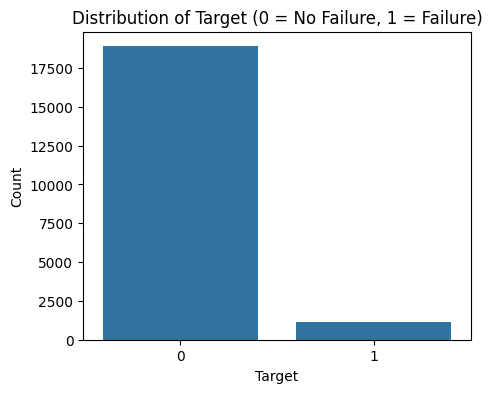

In [15]:
# Distribution of the target variable
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Target", data=df)
plt.xlabel("Target")
plt.ylabel("Count")
plt.title("Distribution of Target (0 = No Failure, 1 = Failure)")
plt.show()

We see here that the Target is heavily imbalanced.

**Distribution of all 40 predictor columns**

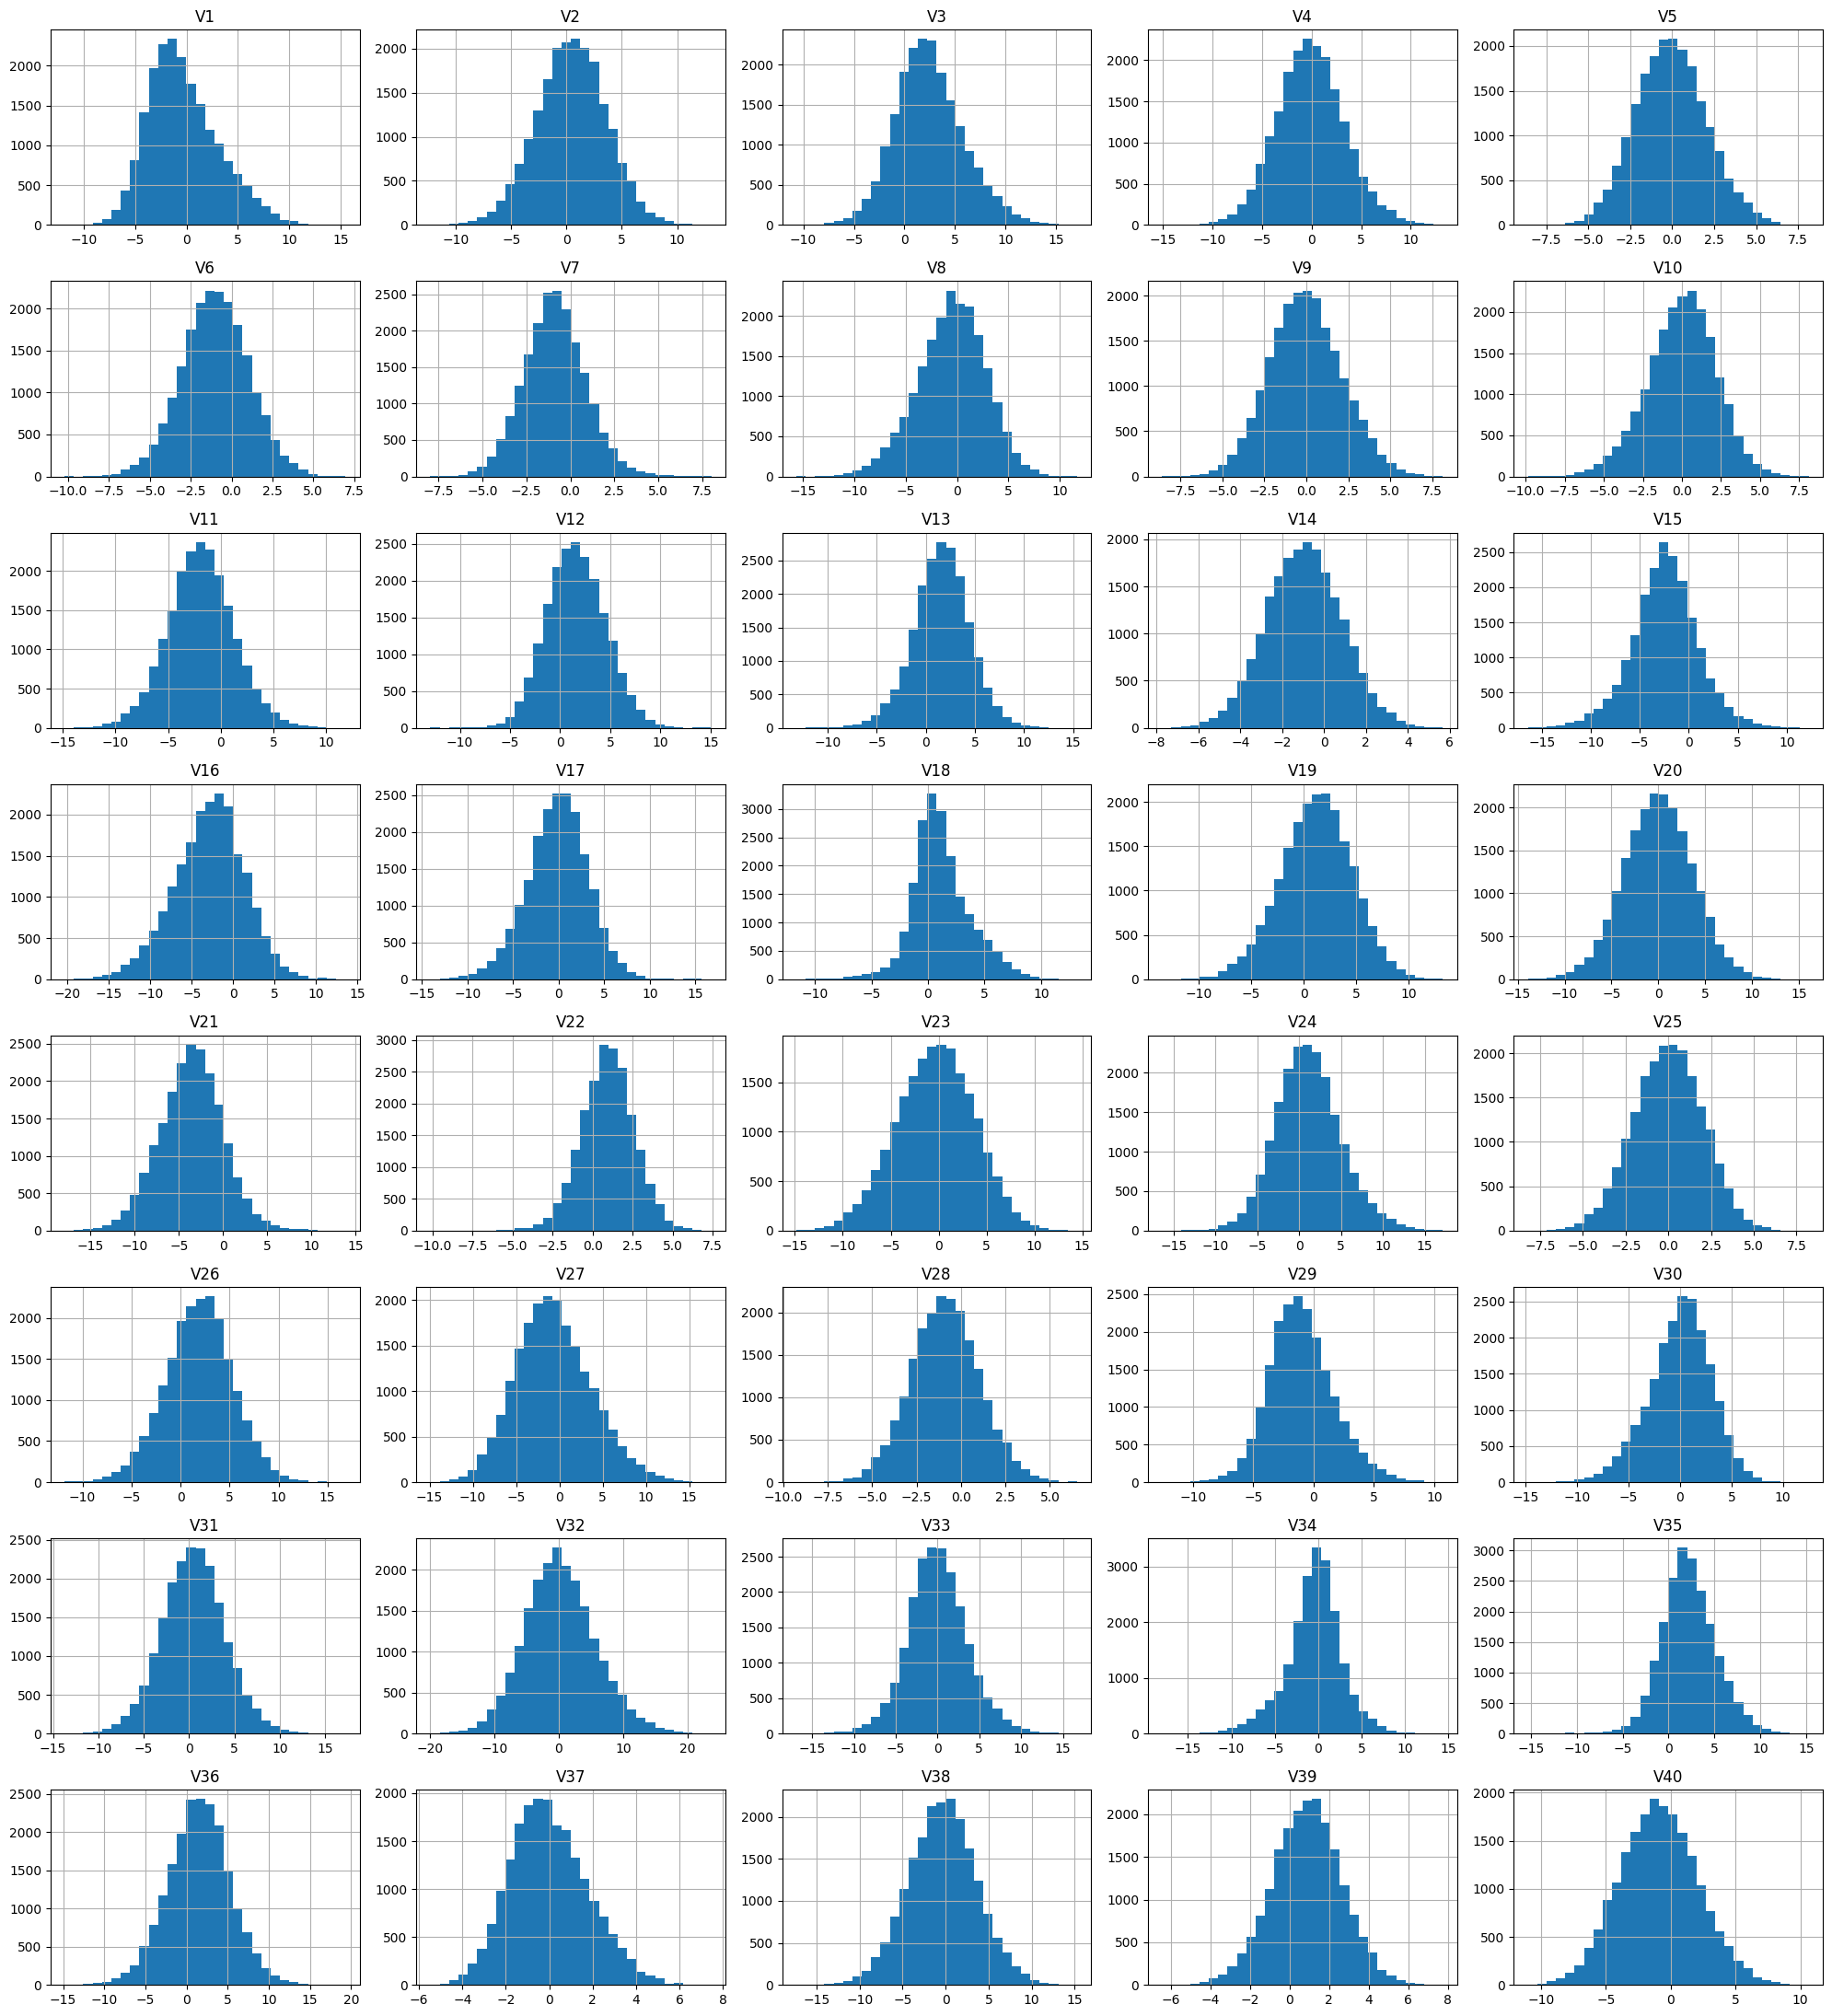

In [16]:
# Distribution of all 40 predictor variables
df.drop(columns=["Target"]).hist(figsize=(20, 22), bins=30, layout=(8, 5))
plt.tight_layout()
plt.show()

Looks like the other columns for prediction are pretty much bell shaped, with some mild skewing and outliers.

**Use BoxPlot on the prediction columns to find outliers**

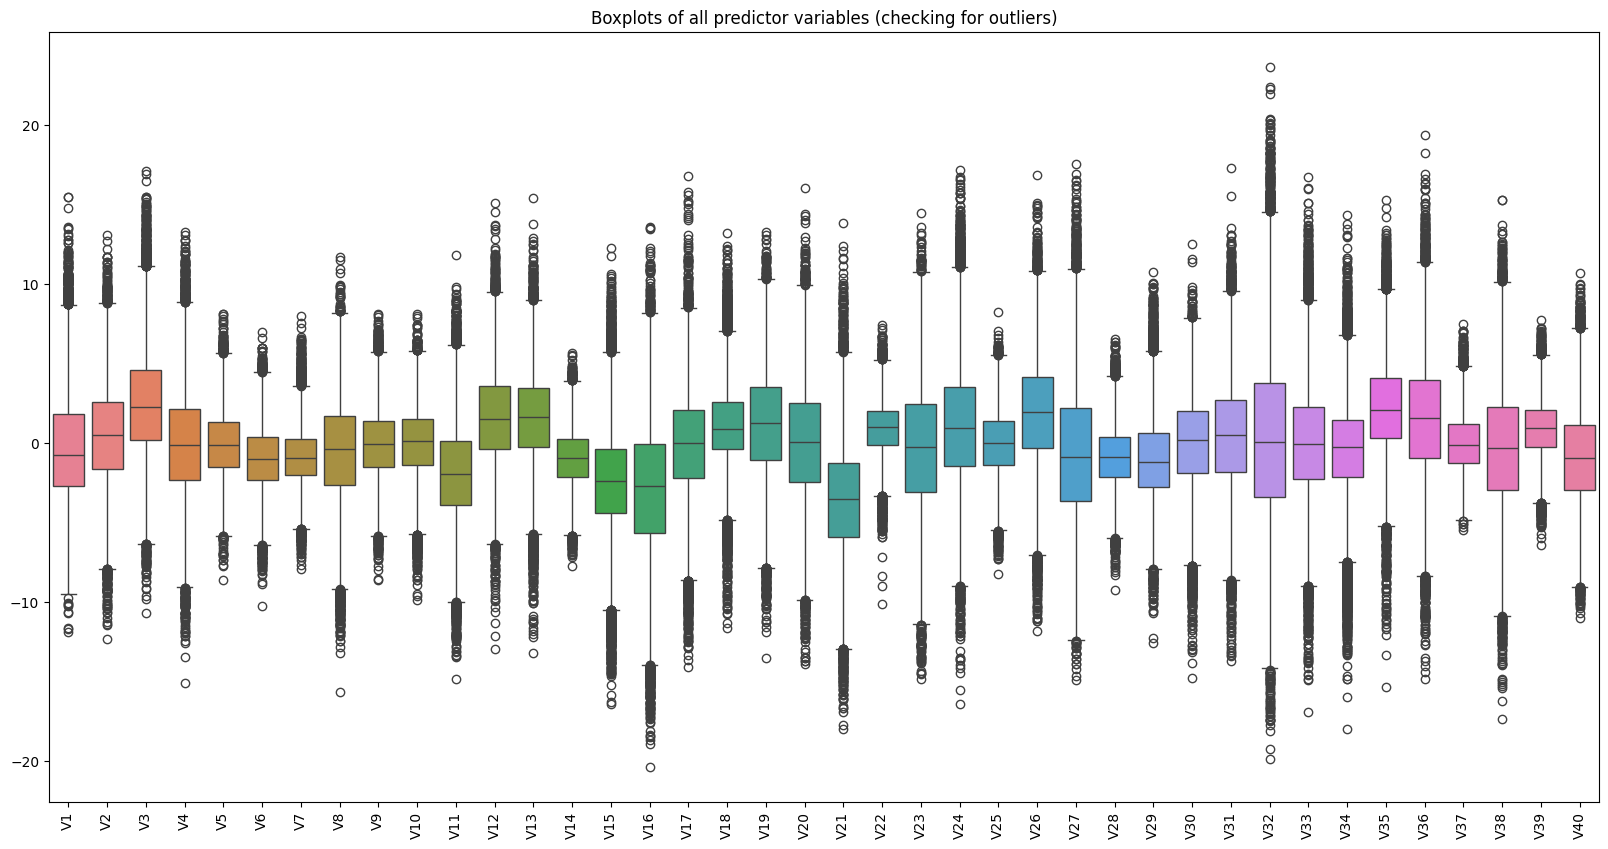

In [17]:
# Boxplots of all predictors to check for outliers
plt.figure(figsize=(20, 10))
sns.boxplot(data=df.drop(columns=["Target"]))
plt.xticks(rotation=90)
plt.title("Boxplots of all predictor variables (checking for outliers)")
plt.show()

In [18]:
#Do we need to transform any of the columns with all the outliers present?
numeric_cols = df.select_dtypes(include=['float64']).columns #leaving out int64 as that is the Target column

print("Distribution and outlier scan")
for col in numeric_cols:
    skew = df[col].skew()

    # Calculate IQR boundaries
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_pct = (len(outliers) / len(df)) * 100

    print(f"\nFeature: {col}")
    print(f"  - Skewness Score: {skew:.2f} (Ideal is closer to 0)")
    print(f"  - Outlier Count: {len(outliers)} rows ({outlier_pct:.1f}% of total data)")
    if abs(skew) > 1:
        print(f" Recommendation: May need to apply a Log Transform before training.")

Distribution and outlier scan

Feature: V1
  - Skewness Score: 0.55 (Ideal is closer to 0)
  - Outlier Count: 214 rows (1.1% of total data)

Feature: V2
  - Skewness Score: -0.04 (Ideal is closer to 0)
  - Outlier Count: 182 rows (0.9% of total data)

Feature: V3
  - Skewness Score: 0.32 (Ideal is closer to 0)
  - Outlier Count: 275 rows (1.4% of total data)

Feature: V4
  - Skewness Score: 0.10 (Ideal is closer to 0)
  - Outlier Count: 228 rows (1.1% of total data)

Feature: V5
  - Skewness Score: 0.13 (Ideal is closer to 0)
  - Outlier Count: 113 rows (0.6% of total data)

Feature: V6
  - Skewness Score: -0.03 (Ideal is closer to 0)
  - Outlier Count: 155 rows (0.8% of total data)

Feature: V7
  - Skewness Score: 0.18 (Ideal is closer to 0)
  - Outlier Count: 291 rows (1.5% of total data)

Feature: V8
  - Skewness Score: -0.26 (Ideal is closer to 0)
  - Outlier Count: 191 rows (1.0% of total data)

Feature: V9
  - Skewness Score: 0.10 (Ideal is closer to 0)
  - Outlier Count: 148 row

In [19]:
#Check for unique values
print("Unique value counts per column")

for col in df.columns:
    print(f"{col:<25} : {df[col].nunique()} unique values")

Unique value counts per column
V1                        : 19982 unique values
V2                        : 19982 unique values
V3                        : 20000 unique values
V4                        : 20000 unique values
V5                        : 20000 unique values
V6                        : 20000 unique values
V7                        : 20000 unique values
V8                        : 20000 unique values
V9                        : 20000 unique values
V10                       : 20000 unique values
V11                       : 20000 unique values
V12                       : 20000 unique values
V13                       : 20000 unique values
V14                       : 20000 unique values
V15                       : 20000 unique values
V16                       : 20000 unique values
V17                       : 20000 unique values
V18                       : 20000 unique values
V19                       : 20000 unique values
V20                       : 20000 unique values
V21      

**OBSERVATIONS**:

1. The Target is imbalanced and we need to probably weight it during model building

2. We see most of the prediction values are bell shaped

3. The boxplot shows there are a number of outliers, and we need to be careful with them as they are consistent across the board, maybe they are early detections of some kind.

4. Also checked on the Skewness score but nothing outside the range where we would need to review and possibly treat but as there was nothing we are good

5. The unique values confirms what was expected, and V1 and V2 are missing values, that is why they are less.


## Bivariate Analysis

**Heatmap the Prediction Values with Target**

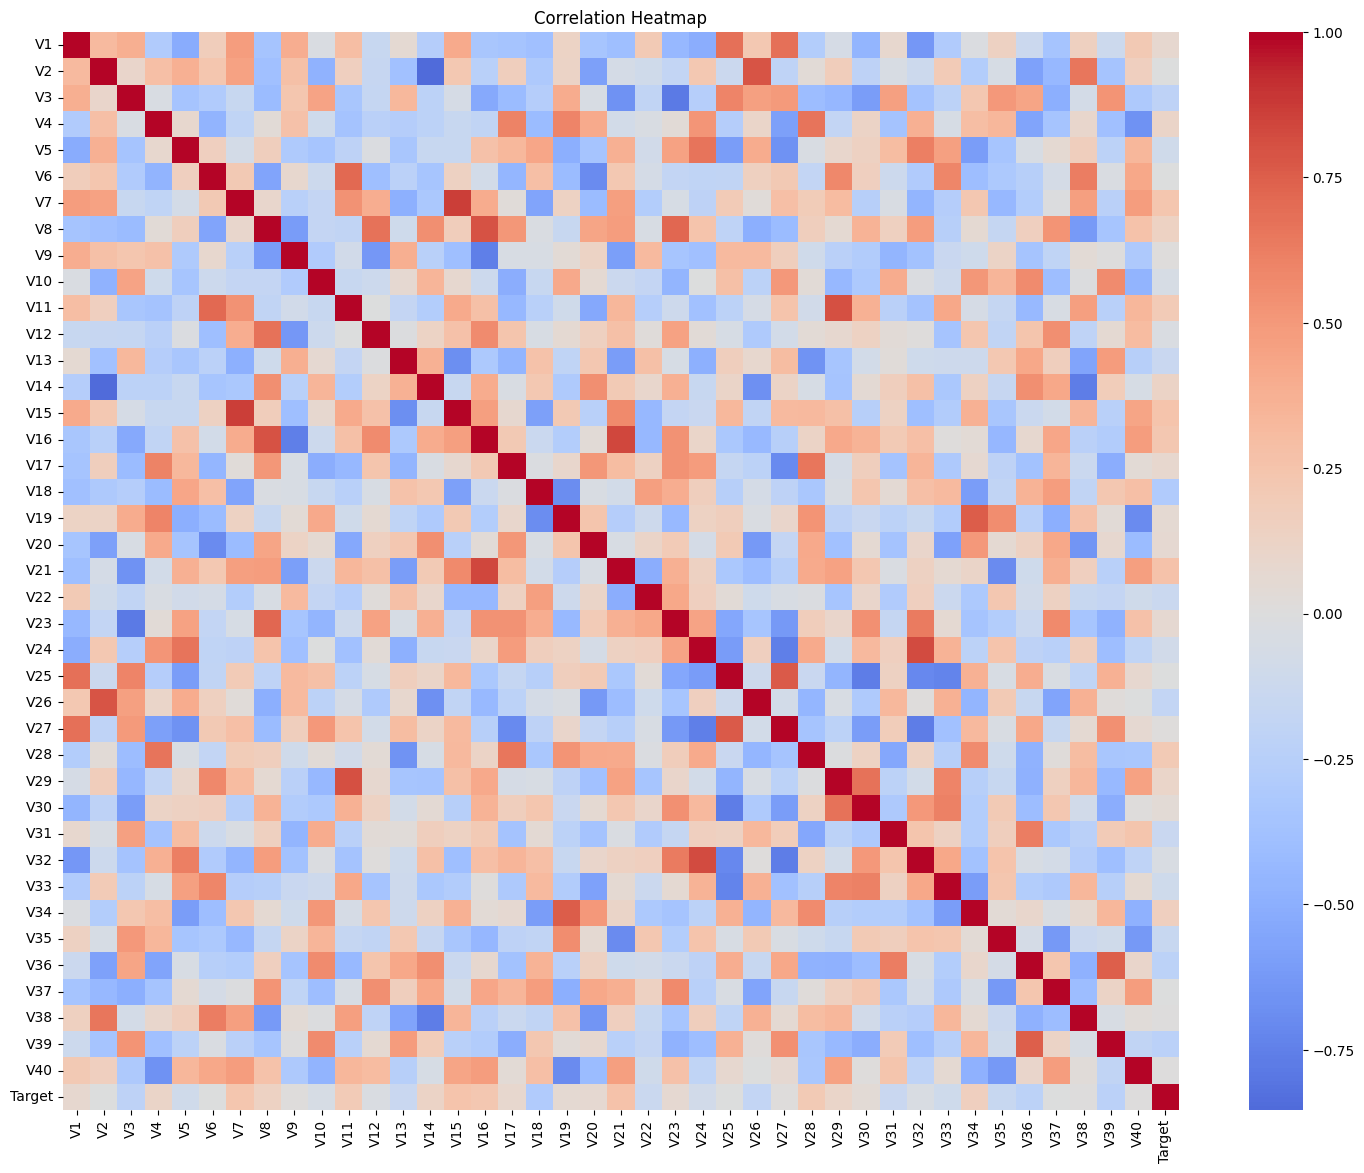

In [20]:
# Correlation heatmap of all variables (including Target)
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap")
plt.show()

No strong coorelation is found here

**Correlation of the Target with the Predictors**

In [21]:
# Correlation of Target and Predictors
target_corr = df.corr(numeric_only=True)["Target"].drop("Target").sort_values(ascending=False)
print("Top 10 positively correlated features with Target:")
print(target_corr.head(10))
print("\nTop 10 negatively correlated features with Target:")
print(target_corr.tail(10))

Top 10 positively correlated features with Target:
V21    0.256411
V15    0.249118
V7     0.236907
V16    0.230507
V28    0.207359
V11    0.196715
V34    0.153854
V8     0.135996
V14    0.117586
V4     0.110786
Name: Target, dtype: float64

Top 10 negatively correlated features with Target:
V33   -0.102548
V22   -0.134727
V31   -0.136951
V13   -0.139718
V35   -0.145603
V26   -0.180469
V3    -0.213855
V36   -0.216453
V39   -0.227264
V18   -0.293340
Name: Target, dtype: float64


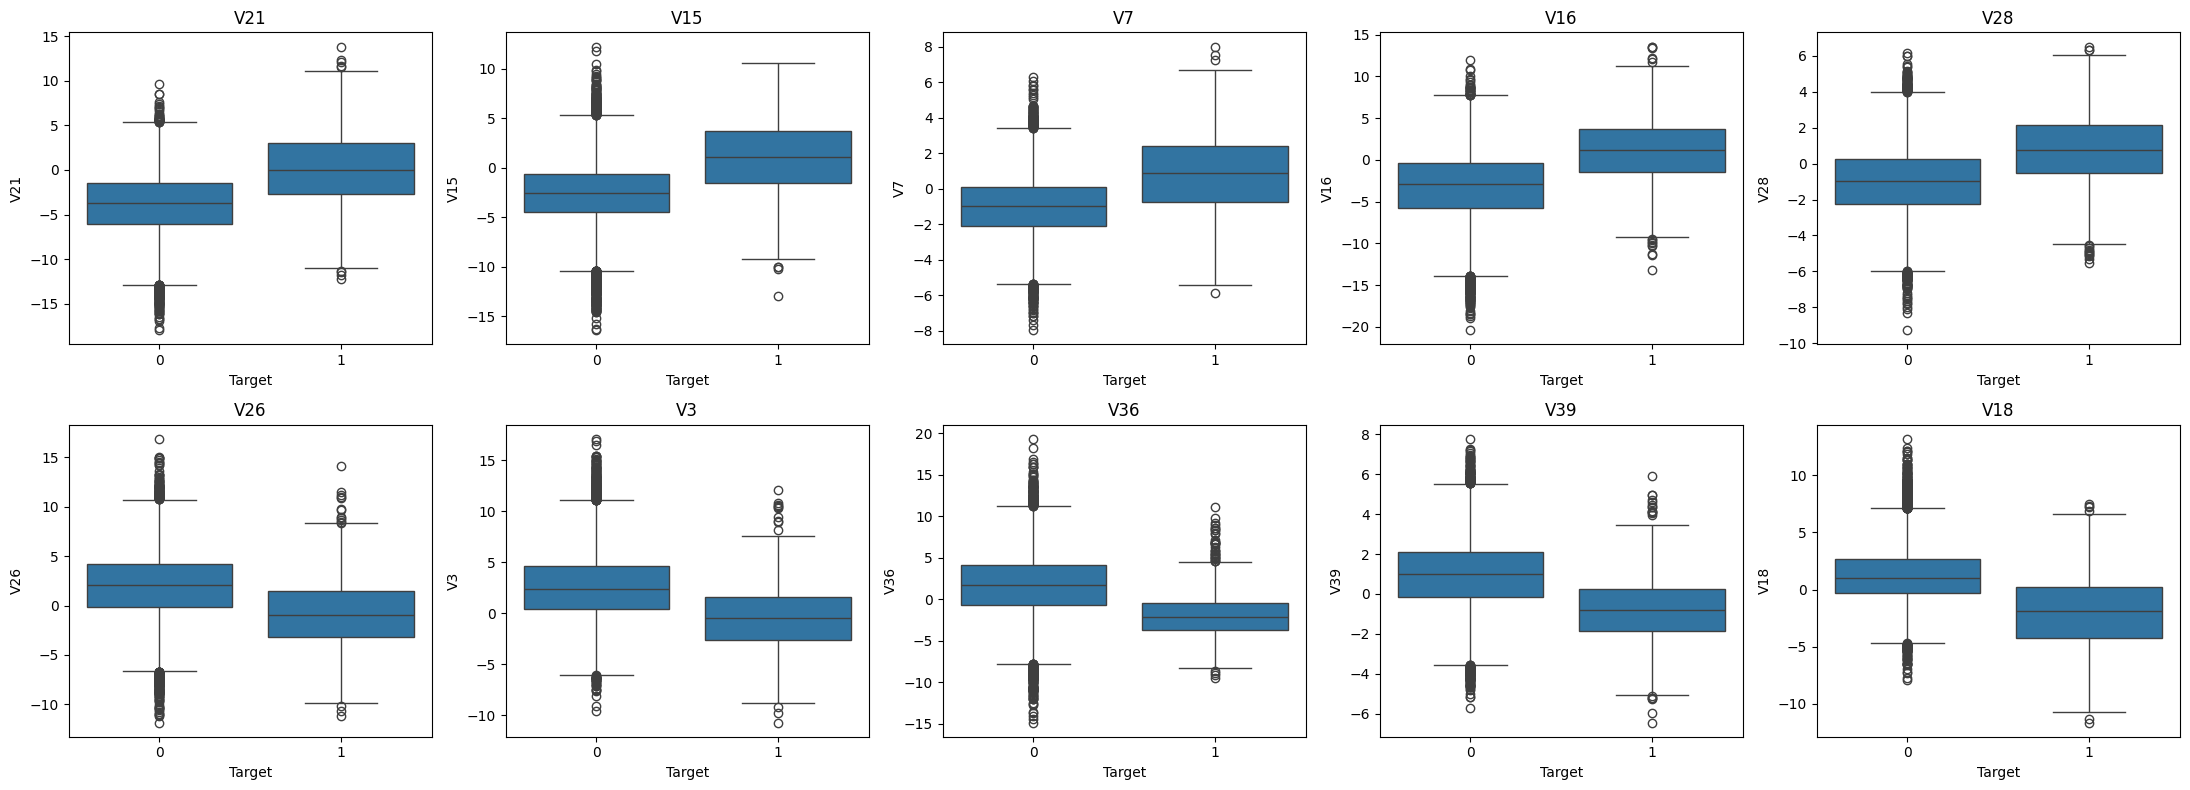

In [22]:
#Lets BoxPlot these top ones:
top_features = pd.concat([target_corr.head(5), target_corr.tail(5)]).index.tolist()

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, feat in zip(axes.flatten(), top_features):
    sns.boxplot(x="Target", y=feat, data=df, ax=ax)
    ax.set_title(feat)
plt.tight_layout()
plt.show()


**Observations:**

1. We really don't see any of the predictor values standing out as being a go-to predictor value.

2. V21, V15, V7, V16, V28 have the strongest positive association with failure.

3. V18, V39, V36, V3, V26 have the strongest negative association.

4. The boxplot shows a shift with the target for positive and negative, which means this is a good sign for us for the model.

5. The heatmap shows us that we most likely do not need to drop any of of the values as they are mostly uniform.

# **Data Preprocessing**

In [23]:
#Lets set up our training and test, we will drop Target, and then split the data.
#Training Data drop Target (use X and y for now - split/validation sets next from these)
X = df.drop(columns=["Target"])
y = df["Target"]
#Test Data drop Target
X_test = dftest.drop(columns=["Target"])
y_test = dftest["Target"]

#Split the training data into train/validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

#here is what we have:
#X_train, y_train
#X_val, y_val

#Look at what we have:
print("X_train (split) shape:", X_train.shape)
print("X_val (split) shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train (split) shape: (15000, 40)
X_val (split) shape: (5000, 40)
X_test shape: (5000, 40)


In [24]:
#Missing Values- we know we have missing values in V1 and V2 (18 each)
#We will use Median strategy to fill, and ensure that we impute on the sets directly to avoid leakage

imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

print("Any missing values left in X_train?", np.isnan(X_train_imp).sum())
print("Any missing values left in X_val?", np.isnan(X_val_imp).sum())
print("Any missing values left in X_test?", np.isnan(X_test_imp).sum())


Any missing values left in X_train? 0
Any missing values left in X_val? 0
Any missing values left in X_test? 0


In [25]:
#Now we can SCALE since the missing values are taken care of
#Scale Fit directly to Train so no data leakage, use the StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)
X_test_scaled = scaler.transform(X_test_imp)

print("Scaled train mean (should be 0):", np.round(X_train_scaled.mean(), 3))
print("Scaled train std (should be 1):", np.round(X_train_scaled.std(), 3))




Scaled train mean (should be 0): -0.0
Scaled train std (should be 1): 1.0


Scale Fit directly to Train so no data leakage

In [26]:
#Class weighting to help offset the low failure - compute them now, we will use them later

class_wts = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train)

class_weight_dict = {0: class_wts[0], 1: class_wts[1]}

print("Class weights (as 'failure' is so low):")

print(class_weight_dict)



Class weights (as 'failure' is so low):
{0: np.float64(0.5293619424054207), 1: np.float64(9.014423076923077)}


**NOTES**:

1. Train was split into a training set of 75% and a validation set of 25% so that the failure rate is kept at 5% for both.

2. The validation set will be used to tune and compare

3. The imputer was FIT (get the mean and standard deviation) only on the training set and then transformed (applied) on the test and validation sets to prevent leakage.

4. The scaler was wth same Fit on the training and transformed on the test and validation.

5. The class weight was computed on the training

# **Model Building**

## Model Evaluation Criterion

**Our Measurements:**

The cost ordering is:
Inspection Cost < Repair Cost < Replacement Cost.

FN - False Negative: a real problem, a failure of the machine that the model misses. Leads to break down and replacement, the most expensive outcome.

TP - True Positive: a correctly caught failure - this means repair (and then inspection). The moderate cost.

FP - False Positive: a false alarm - but will lead to inspection. Least expensive, but still a false result.


Therefore, we need to focus the Recall on the Failure Class, this is our primary metric.

Maximizing the Recall here minimizes the the (FN), the most expensive outcome.

Accuracy will not be a good metric, as the data is imbalanced, so we could just do nothing and be correct 95% of the time.

Precision and F1 will be used to keep (FP) low, and will use F1 to tie break and models with same recall values.



## Initial Model Building (Model 0)

- Let's start with a neural network consisting of
  - just one hidden layer
  - activation function of ReLU
  - SGD as the optimizer

===== Baseline Model 0 (1 hidden layer, ReLu, SGD) =====
Epochs run: 100

Validation set classification report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      4722
     Failure       0.97      0.80      0.88       278

    accuracy                           0.99      5000
   macro avg       0.98      0.90      0.94      5000
weighted avg       0.99      0.99      0.99      5000



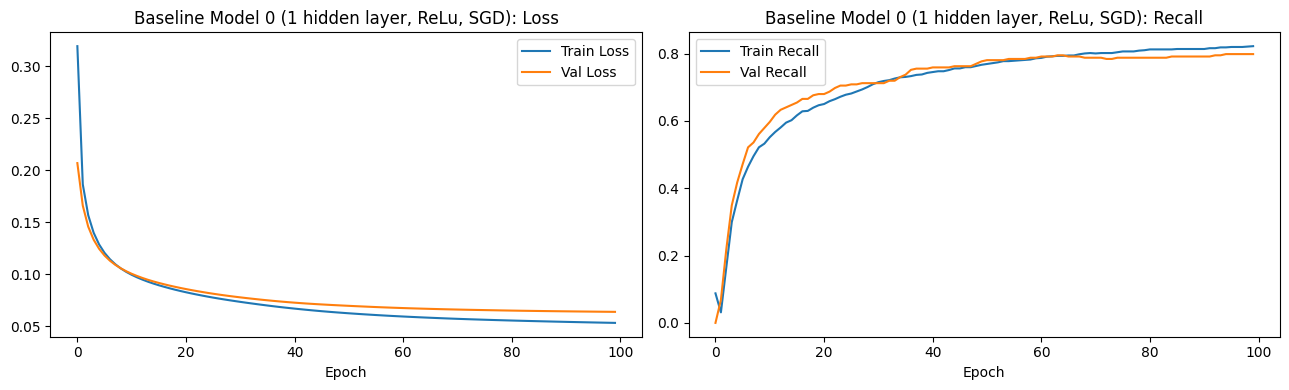

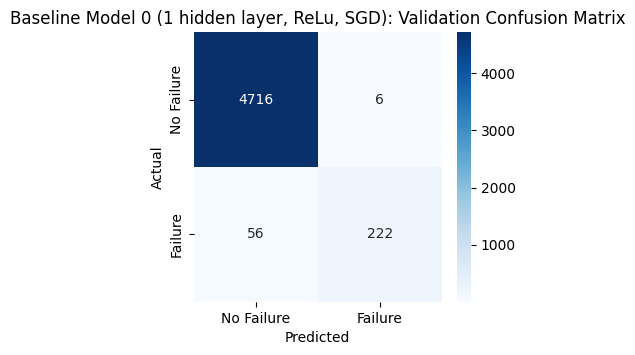

In [27]:
#BASE MODEL: Just One Hidden Layer - ReLU - SGD as optimizer
#Model 0: 1 hidden layer (32 neurons, ReLU), SGD optimizer, no dropout, no class weights
#use pre-built function(s) *(takes about 30 seconds to run)

model_0 = build_ann(hidden_layers=[32], optimizer=keras.optimizers.SGD(learning_rate=0.01))

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history_0 = model_0.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100, batch_size=64,
    callbacks=[early_stop],
    verbose=0,
)

_ = evaluate_and_store("Baseline Model 0 (1 hidden layer, ReLu, SGD)", model_0, history_0, model_performance)

**Model 0:**

Single 32 Neuron hidden layer trained with plain SGD, Recall (FN) was good. This model will serve as our reference point going forward.

# **Model Performance Improvement**

## Model 1

===== Model 1 (64,32,16 HiddenLayers, SGD) =====
Epochs run: 100

Validation set classification report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00      4722
     Failure       0.99      0.85      0.92       278

    accuracy                           0.99      5000
   macro avg       0.99      0.93      0.96      5000
weighted avg       0.99      0.99      0.99      5000



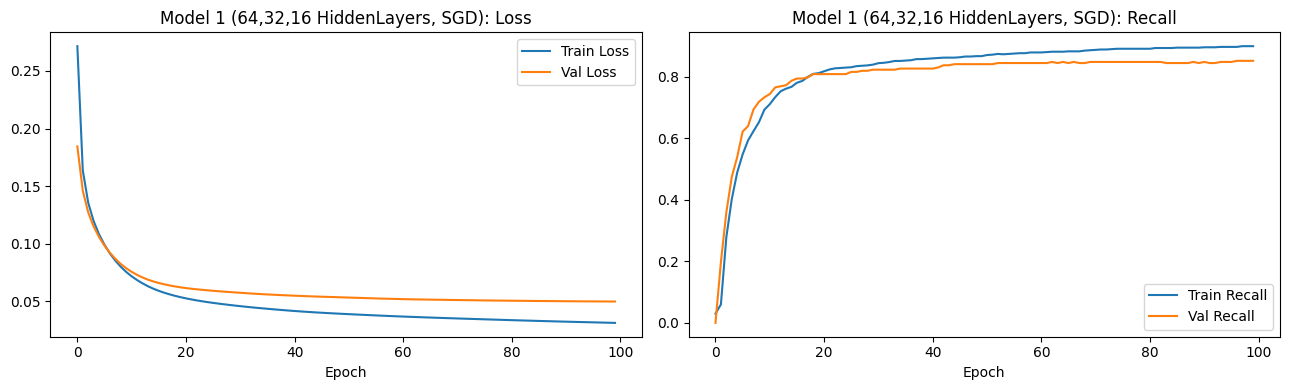

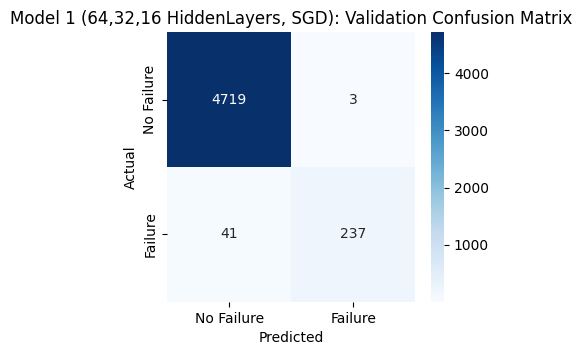

In [28]:
#MODEL 1
#Model 1 - we will add more hidden layers (64,32,16), still use SGD, no dropout no weights
#use pre-built function(s) *(takes about 60 seconds to run)

model_1 = build_ann(hidden_layers=[64, 32, 16], optimizer=keras.optimizers.SGD(learning_rate=0.01))

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history_1 = model_1.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100, batch_size=64,
    callbacks=[early_stop],
    verbose=0,
)

_ = evaluate_and_store("Model 1 (64,32,16 HiddenLayers, SGD)", model_1, history_1, model_performance)

Model 1 has improvements across Recall and F1 compared to the baseline Model 0

## Model 2

===== Model 2 (model1 structure but with Adam instead of SGD) =====
Epochs run: 17

Validation set classification report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00      4722
     Failure       0.98      0.85      0.91       278

    accuracy                           0.99      5000
   macro avg       0.99      0.93      0.95      5000
weighted avg       0.99      0.99      0.99      5000



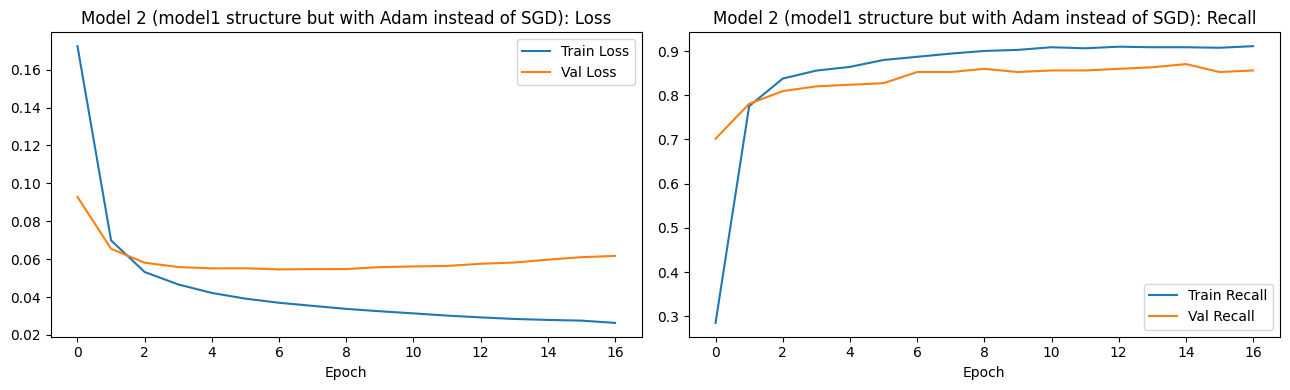

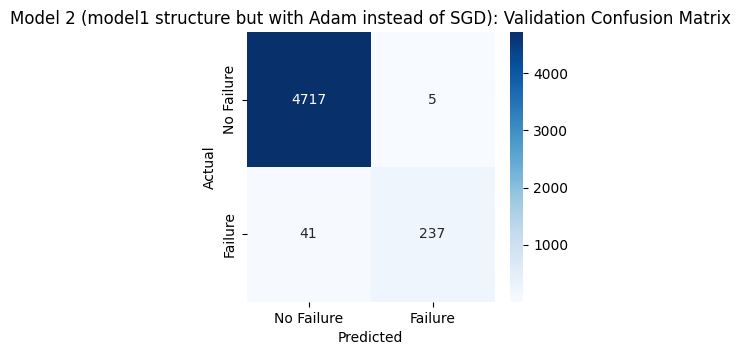

In [29]:
#MODEL 2
#Model 2: Keep structure and hidden layers same as Model 1 (64,32,16), but use Adam optimizer instead of SGD
#use pre-built function(s) *(takes about 30 seconds to run)

model_2 = build_ann(hidden_layers=[64, 32, 16], optimizer=keras.optimizers.Adam(learning_rate=0.001))

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history_2 = model_2.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100, batch_size=64,
    callbacks=[early_stop],
    verbose=0,
)

_ = evaluate_and_store("Model 2 (model1 structure but with Adam instead of SGD)", model_2, history_2, model_performance)

This model ran / executed faster than the previous but overfitting is seen here more

## Model 3

===== Model 3 (Use Adam and add Dropout .2) =====
Epochs run: 22

Validation set classification report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00      4722
     Failure       0.98      0.86      0.92       278

    accuracy                           0.99      5000
   macro avg       0.99      0.93      0.96      5000
weighted avg       0.99      0.99      0.99      5000



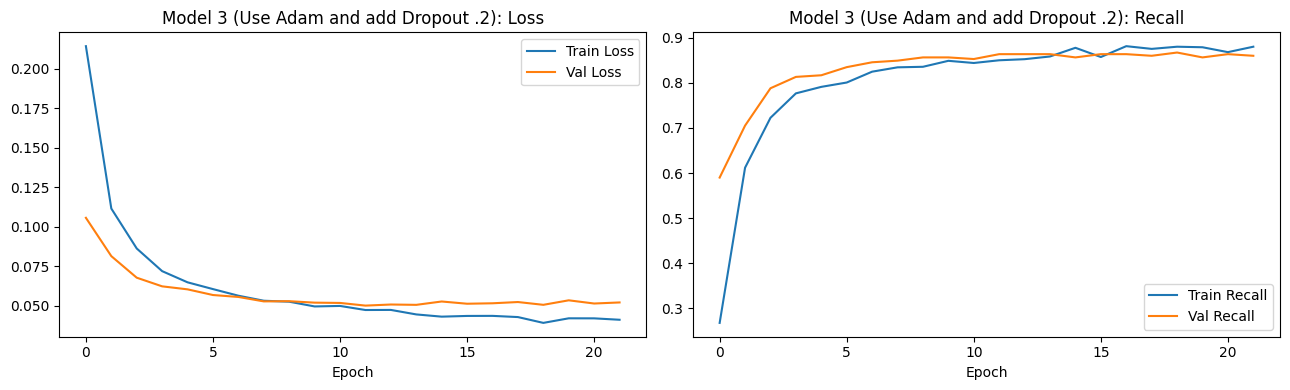

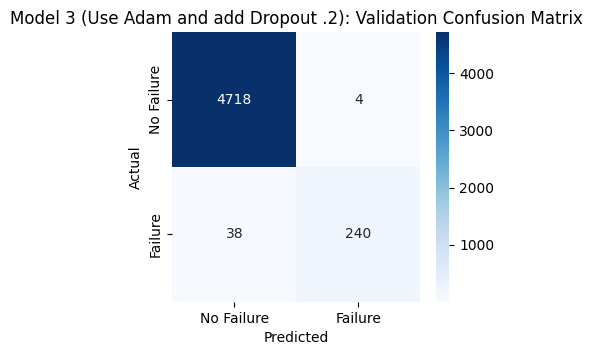

In [30]:
#MODEL 3
#Model 3: Keep structure and hidden layers same as Model 1 (64,32,16), use Adam optimizer instead of SGD
#and adding Dropout (rate 0.2) after every hidden layer to help reduce overfitting.
#use pre-built function(s) *(takes about 40 seconds to run)

model_3 = build_ann(hidden_layers=[64, 32, 16], optimizer=keras.optimizers.Adam(learning_rate=0.001), dropout=0.2)

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history_3 = model_3.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100, batch_size=64,
    callbacks=[early_stop],
    verbose=0,
)

_ = evaluate_and_store("Model 3 (Use Adam and add Dropout .2)", model_3, history_3, model_performance)

We can see some improvements in the confusion matrix and overfitting is reduced, and we are getting better recall and F1.

## Model 4

===== Model 4 (Adam + Class Weights no Dropout) =====
Epochs run: 29

Validation set classification report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      4722
     Failure       0.94      0.86      0.90       278

    accuracy                           0.99      5000
   macro avg       0.97      0.93      0.95      5000
weighted avg       0.99      0.99      0.99      5000



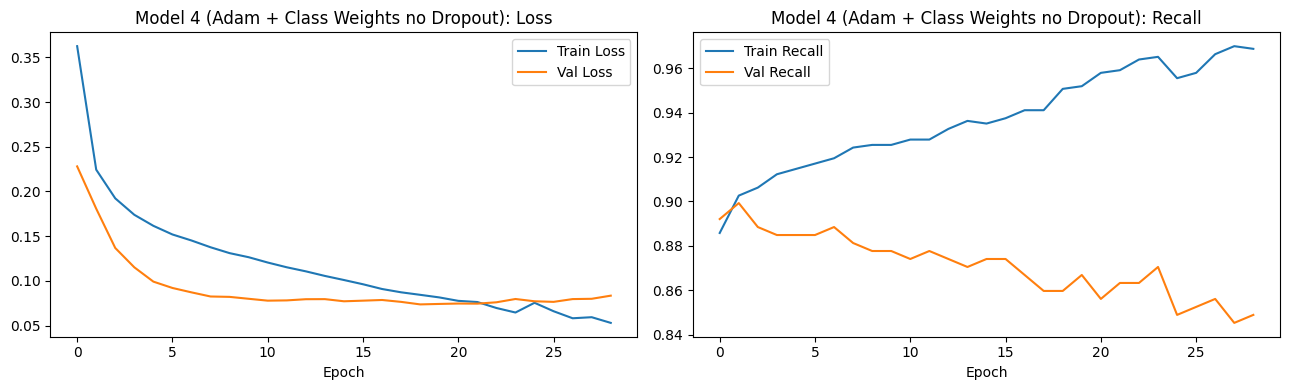

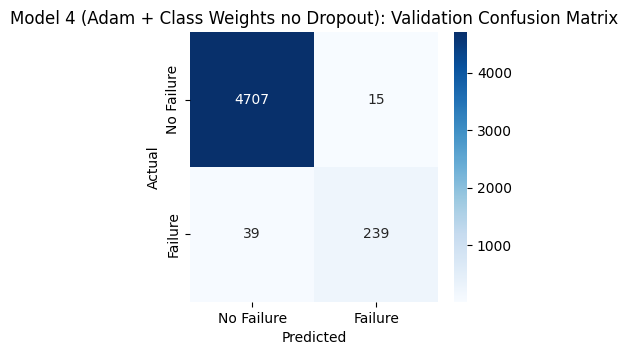

In [31]:
#MODEL 4
#Model 4: Keep structure and hidden layers same as Model 1 (64,32,16), use Adam optimizer instead of SGD
#Remove the Dropout Rate
#Add in Class Weight - from the weights we generated during data preprosing, this will force attention on failure so Recall should improve
#use pre-built function(s) *(takes about 40 seconds to run)

model_4 = build_ann(hidden_layers=[64, 32, 16], optimizer=keras.optimizers.Adam(learning_rate=0.001))

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history_4 = model_4.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100, batch_size=64,
    callbacks=[early_stop],
    class_weight=class_weight_dict,
    verbose=0,
)

_ = evaluate_and_store("Model 4 (Adam + Class Weights no Dropout)", model_4, history_4, model_performance)

We have still good recall, but we are overfit

## Model 5

===== Model 5 (Adam + Dropout + Class Weights) =====
Epochs run: 31

Validation set classification report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      4722
     Failure       0.95      0.88      0.91       278

    accuracy                           0.99      5000
   macro avg       0.97      0.94      0.95      5000
weighted avg       0.99      0.99      0.99      5000



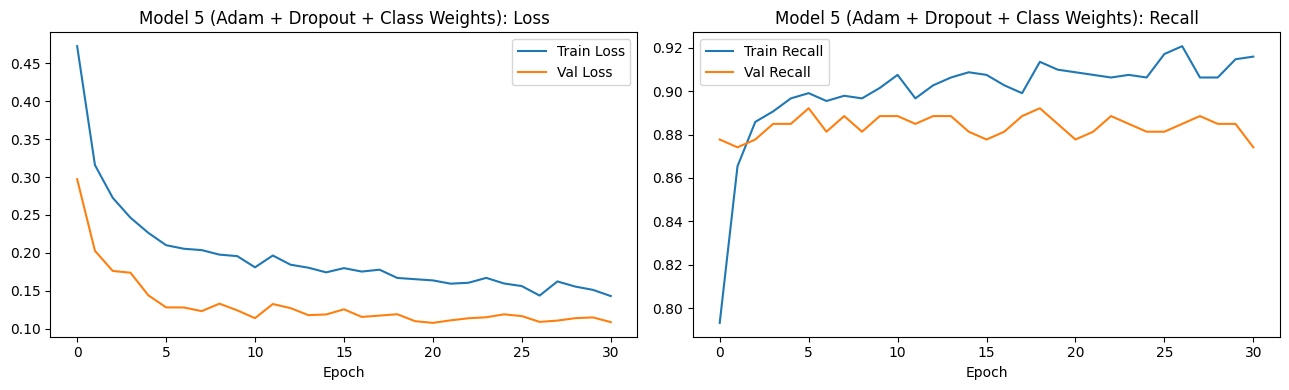

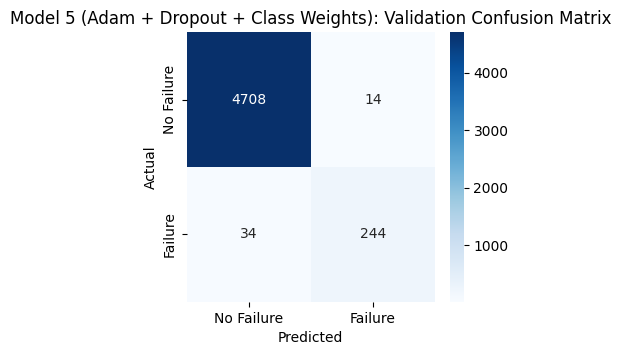

In [32]:
#MODEL 5
#Model 5: Keep structure and hidden layers same as Model 1 (64,32,16), use Adam optimizer instead of SGD
#Add back in the Dropout Rate! Keep in Class Weight - lets see what happens
#use pre-built function(s) *(takes about 40 seconds to run)

model_5 = build_ann(hidden_layers=[64, 32, 16], optimizer=keras.optimizers.Adam(learning_rate=0.001), dropout=0.2)

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history_5 = model_5.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100, batch_size=64,
    callbacks=[early_stop],
    class_weight=class_weight_dict,
    verbose=0,
)

_ = evaluate_and_store("Model 5 (Adam + Dropout + Class Weights)", model_5, history_5, model_performance)

We are seeing improvements with the overfitting, and our recall and F1 values are good.

## Model 6

===== Model 6 (More Layers - Lower Adam and Dropout - Class Weight) =====
Epochs run: 32

Validation set classification report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      4722
     Failure       0.94      0.88      0.91       278

    accuracy                           0.99      5000
   macro avg       0.97      0.94      0.95      5000
weighted avg       0.99      0.99      0.99      5000



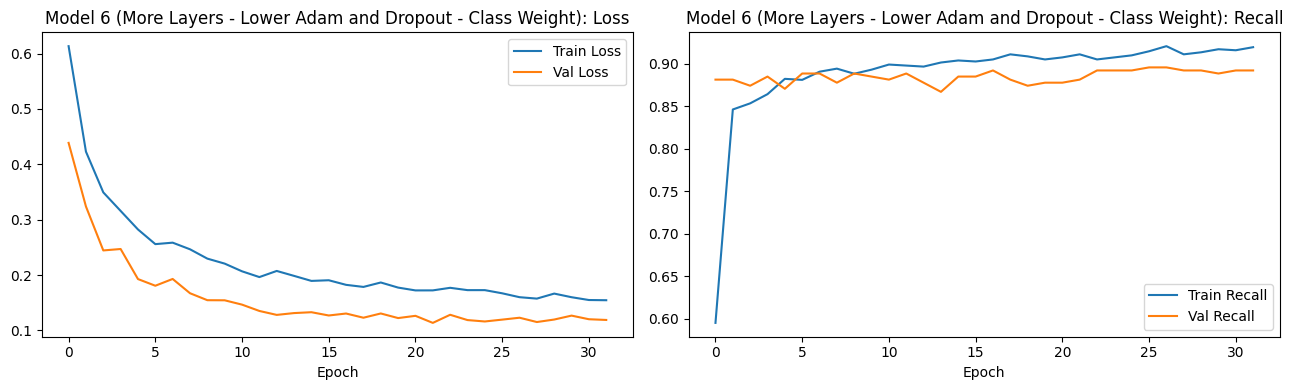

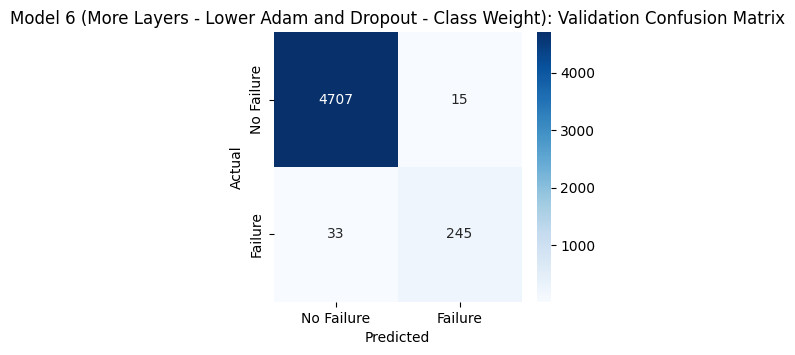

In [33]:
#MODEL 6
#Model 6: Change up and add 128 to hidden layers (128,64,32,16)
#Lower Adam optimizer to 0.0005
#Lower the Dropout Rate to 0.3
#Add in Class Weight
#So we have all the improvements placed in this model
#use pre-built function(s) *(takes about 80 seconds to run)

model_6 = build_ann(
    hidden_layers=[128, 64, 32, 16],
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    dropout=0.3,
)

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history_6 = model_6.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=150, batch_size=64,
    callbacks=[early_stop],
    class_weight=class_weight_dict,
    verbose=0,
)

_ = evaluate_and_store("Model 6 (More Layers - Lower Adam and Dropout - Class Weight)", model_6, history_6, model_performance)

This gives us our best Recall score

# **Model Performance Comparison and Final Model Selection**

Now, in order to select the final model, we will compare the performances of all the models for the training and validation sets.

In [34]:
#Use the pre-built model_performance that has been saving the values and have a look via a chart
comparison_df = pd.DataFrame(model_performance).set_index("Model")
comparison_df = comparison_df.sort_values("Val_Recall", ascending=False)
comparison_df.round(3)

,Train_Accuracy,Train_Recall,Train_Precision,Train_F1,Val_Accuracy,Val_Recall,Val_Precision,Val_F1
Model,,,,,,,,
Model 6 (More Layers - Lower Adam and Dropout - Class Weight),0.993,0.915,0.954,0.934,0.990,0.881,0.942,0.911
Model 5 (Adam + Dropout + Class Weights),0.993,0.911,0.955,0.932,0.990,0.878,0.946,0.910
Model 3 (Use Adam and add Dropout .2),0.993,0.881,0.995,0.934,0.992,0.863,0.984,0.920
Model 4 (Adam + Class Weights no Dropout),0.993,0.927,0.952,0.939,0.989,0.860,0.941,0.898
"Model 1 (64,32,16 HiddenLayers, SGD)",0.994,0.891,0.992,0.939,0.991,0.853,0.988,0.915
Model 2 (model1 structure but with Adam instead of SGD),0.992,0.864,0.993,0.924,0.991,0.853,0.979,0.912
"Baseline Model 0 (1 hidden layer, ReLu, SGD)",0.989,0.819,0.986,0.894,0.988,0.799,0.974,0.877


In [35]:
#Select the final model: the one with the highest validation Recall (FN = costliest)
#F1 is the tie-breaker

best_model_name = comparison_df.sort_values(["Val_Recall", "Val_F1"], ascending=False).index[0]
print("Selected final model:", best_model_name)

models_dict = {
    "Baseline Model 0 (1 hidden layer, ReLu, SGD)": model_0,
    "Model 1 (64,32,16 HiddenLayers, SGD)": model_1,
    "Model 2 (model1 structure but with Adam instead of SGD)": model_2,
    "Model 3 (Use Adam and add Dropout .2)": model_3,
    "Model 4 (Adam + Class Weights no Dropout)": model_4,
    "Model 5 (Adam + Dropout + Class Weights)": model_5,
    "Model 6 (More Layers - Lower Adam and Dropout - Class Weight)": model_6,
}
final_model = models_dict[best_model_name]

Selected final model: Model 6 (More Layers - Lower Adam and Dropout - Class Weight)


Model Comparison - Observations:

From the Base Model (0) we saw with Model 1 that there was a validation recall improvement.

When I switched from SGD to Adam in Model 2, speed was improved as Adam gave fewer epochs due to its adaptive learning rate.

For Model 3 adding in Dropout improved recall, then with Model 4 we saw how class weights combined (and when Dropout is left out) that recall is adjusted via the Dropout as it reduces overfitting, and the class weight force penalty on missed failures. Combine them with model 5 saw they worked together.

Model 6 added another hidden layer, lowered Dropout and lowered Adam learning rates, and gave us the best recall while precision and F1 were comparable to the other models.



Now, let's check the performance of the final model on the test set.

Final model: Model 6 (More Layers - Lower Adam and Dropout - Class Weight)

Test set classification report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      4718
     Failure       0.95      0.87      0.91       282

    accuracy                           0.99      5000
   macro avg       0.97      0.93      0.95      5000
weighted avg       0.99      0.99      0.99      5000

Test metrics: {'Accuracy': 0.99, 'Recall': 0.872, 'Precision': 0.95, 'F1': 0.909}


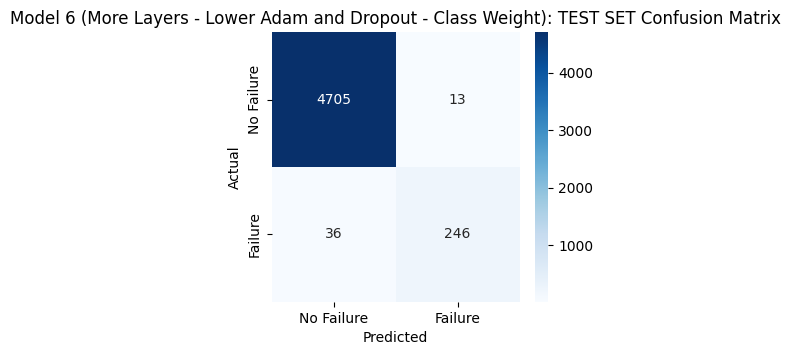

In [36]:
#Running Model 6 on the unused TEST set (used only once, here)
test_pred = (final_model.predict(X_test_scaled, verbose=0) > 0.5).astype(int).ravel()

print(f"Final model: {best_model_name}\n")
print("Test set classification report:")
print(classification_report(y_test, test_pred, target_names=["No Failure", "Failure"]))

test_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Recall": recall_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred),
    "F1": f1_score(y_test, test_pred),
}
print("Test metrics:", {k: round(v, 3) for k, v in test_metrics.items()})

plot_confusion(y_test, test_pred, f"{best_model_name}: TEST SET Confusion Matrix")

Observations on test set performance:

The model performed adequately on the untouched test set, and is in line with our training and validation - so the data is not overfit.

The confusion matrix shows that our False Negative is kept low, which is what we want, at the cost of false positives, which means inspections, but that is the trade off and inspections are less expensive.

The Model 6 confusion matrix was: 4707, 15 | 33, 245

The Test confusion matrix was: 4705, 13 | 36, 246



# **Actionable Insights and Recommendations**

**Key Insights**

Class imbalance is our biggest concern.

As our failure rate is low, 5.6%, focusing on accuracy would give us a high accuracy reading, but this is similar to the scenario of 1 person in 100 having cancer, so if you do nothing you will be right 99% of the time. So focusing on accuracy is not recommended.

Recall is the "failure" class, and is what we should focus on, getting as close as possible with recall will more accurately predict machine failures, which is our most expensive concern.

Our base neural network did well, and our first model where we added more neural layers significantly improved recall. So points us to keeping the structure simple and focus on improvements.

I added improvements to each model, some helped, but each guided me to the final model (6). The process was:

1. Adding more hidden layers gave the network more capacity to learn the patterns that separate failing from healthy generators.

2. Switching from SGD to the Adam optimizer produced faster results but then overfitting became a concern.

3. Dropout reduced overfitting, helping the model to see failure patterns rather than memorizing the training set.
  
4. Adding in Class weights directly told the model that missing a failure is costlier than a false alarm, which is what we are aiming for

5. The final model (Model 6 with more hidden layers, lower Adam and Dropout values, and using Class Weights) gave us the best validation recall of all models tried, while keeping precision/F1 steady, and this performance held up on the untouched test set - indicating a model that will generalize well to new sensor data in production.

**Business Recommendations**

Deploy the final neural network as an early-warning system that will predict generators that need maintenance befoe they break down.

Accept a moderate rate of false alarms as a deliberate trade-off. Since an inspection (the cost of a false positive) is cheaper than either a repair or a replacement, our model, tuned for Recall, will reduce total maintenance cost even though it occasionally may send a technician to inspect a generator that may still be good.

Be sure to keep log of when an inspection showed that the generator needed updates, and when it did not.

Using the predicated probability, the company can create schedules for maintenance.

Schedule recalibrations for the model over time in order to retune and retrain on new data.

For future review, keep a log of the top predication signals (for example, V17 may be a good one), and when retuning the model, additional weights and values can be added to make it even better.

In [37]:
!jupyter nbconvert --to html '/content/drive/MyDrive/Colab Notebooks/INN_ReneWind_Main_Project_FullCode_Notebook.ipynb'

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/INN_ReneWind_Main_Project_FullCode_Notebook.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 20 image(s).
[NbConvertApp] Writing 1946804 bytes to /content/drive/MyDrive/Colab Notebooks/INN_ReneWind_Main_Project_FullCode_Notebook.html
